# DAY 1

In [42]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

In [43]:
# The files have no header row, so we name the columns ourselves
train = pd.read_csv("train.csv", header=None, names=["label", "text"])
test_pool = pd.read_csv("test.csv", header=None, names=["label", "text"])

print("Train rows:", len(train))
print("Test pool rows:", len(test_pool))

Train rows: 560000
Test pool rows: 38000


In [44]:
# In this dataset, 1 = negative and 2 = positive
label_names = {1: "negative", 2: "positive"}

train["y"] = train["label"].map(label_names)
test_pool["y"] = test_pool["label"].map(label_names)

print(train[["label", "y"]].drop_duplicates())

   label         y
0      1  negative
1      2  positive


In [45]:
# Keep 300 reviews from the test file, split evenly between classes.
# The first output (everything else) is not needed, so it goes to "_".
_, test_300 = train_test_split(
    test_pool,
    test_size=300,
    stratify=test_pool["y"],
    random_state=42,
)

test_300.to_csv("test_300.csv", index=False)

print("Test set size:", len(test_300))
print(test_300["y"].value_counts())

Test set size: 300
y
negative    150
positive    150
Name: count, dtype: int64


In [46]:
# 1. Class balance
print("Class balance:")
print(train["y"].value_counts(normalize=True))

# 2. Average review length
print("\nAverage length:", round(train["text"].str.len().mean()), "characters")

# 3. Missing text
print("Missing texts:", train["text"].isna().sum())

# 4. Ten random examples per class
for name in ["negative", "positive"]:
    print(f"\n--- 10 random {name} examples ---")
    examples = train[train["y"] == name].sample(10, random_state=1)
    for text in examples["text"]:
        print("-", text[:150])

Class balance:
y
negative    0.5
positive    0.5
Name: proportion, dtype: float64

Average length: 726 characters
Missing texts: 0

--- 10 random negative examples ---
- Wow. Talk about disappointing!! We tried to go once, but the line was ridiculous, so we tried a different day hoping that it would be mind blowing. It
- I recently stayed at the MGM Grand and was surprised at how dated and worn the rooms were.\n\nThere were scuffs on the walls and blisters on the furni
- The staff is incompetent, I will never go here again. The sushi is mediocre at best -- there are much better Japanese restaurants in Madison, stay cle
- If you've been to Olive Garden, you've been here and you probably paid less for the same food and better service. \n\nThe only reason I can see people
- My husband and I went on a tour over a month ago.  The front desk staff is rather icy. Our tour guide was nice however.  We got a week guest pass in t
- I have never written a negative review and feel badly for doing s

In [47]:
hard_texts = [
    "The food was not bad at all.",                      # negation
    "Oh great, another hour-long wait for cold fries.",  # sarcasm
    "Lovely staff, but the pasta was a disaster.",       # mixed
    "I wouldn’t say the service was good.",
    "The soup was not bad at all.",
    "Terrible parking, but the food was worth every minute.",
    "Wow, I love paying $30 for a lukewarm burger.",
    "Absolutely the best burger in town!",
    "The steak was alright but I had better.",
    "I found the texture of the food to tough.",
    "I wish the service was better.",
    "The selection of the menu was limited.",
    "The preperation time for the food took a while.",
    "The taste of the food was supprisingly satisfying.",
    "They provided grate value for the prices of their food.",
    "The allowed for special orders to accomidate my needs.",
    "Their selection of beverages was severly limited.",
    "I found both the service and the food as average",
    "Everything that they provided was expetional!",
    "The provided incredible customer service!",
    "The atmosphere didn't match the food at all",
    "They didn't provide any options for milder flavors of noodles",
    "The pasta came out a little overcooked in my opinion",
    "The seafood selection was didn't have a non-shellfish option",
    "The buffet had a large selection but the quality wasn't better than average",
    "The quality of food and services was worth the high price point",
    "I would highly recommend visting for both the food and ambiance at least once",
    "Their approach was both unique and a must visit if you're in the area",
    "Their barbeque is some of the best i have eaten while on vacation",
    "The service was almose immediate with how fast everything was prepared."
]

hard_labels = [
    "positive",
    "negative",
    "negative",
    "negative",
    "positive",
    "positive",
    "negative",
    "positive",
    "positive",
    "negative",
    "negative",
    "negative",
    "negative",
    "positive",
    "positive",
    "positive",
    "negative",
    "negative",
    "positive",
    "posotive",
    "negative",
    "negative",
    "negative",
    "negative",
    "negative",
    "positive",
    "positive",
    "positive",
    "positive",
    "positive"
]

print(len(hard_texts), len(hard_labels))
assert len(hard_texts) == len(hard_labels), "Texts and labels don't match!"

hard = pd.DataFrame({"text": hard_texts, "y": hard_labels})
hard.to_csv("hard_cases.csv", index=False)

30 30


## EDA Notes

- Dataset: Yelp polarity reviews (train.csv / test.csv), binary sentiment.
  Train has 560,000 reviews and the test file has 38,000 reviews (from len() in my Day 1 output).
- Labels: 1 = negative, 2 = positive. No neutral class.
  I added a readable column "y" (negative/positive) and kept the original label column.
- Class balance: train is 50/50. test_300 is 150 negative / 150 positive.
- Average review length: about 726 characters, so reviews are long.
- Missing text: 0.
- Observations from reading 10 random reviews per class (train only):
  - They weren't always focused on the food, some also placed emphesis on the location.
  - Some included personal experinces tha influnced their review.
  - Service of the restauraunt was seen to contribute along side the food.
- Possible label noise: some reviews look mixed or opposite to their label
  (e.g. one positive-labeled review described dry, flavorless food).
- Test set: 300 examples drawn from test.csv with train_test_split
  (stratified, random_state=42), saved as test_300.csv. All models are scored on this
  same file. I did not look at it while building anything.
- Hard cases: 30 sentences I wrote myself (not taken from the dataset), labeled
  positive or negative before running any model. They cover negation, sarcasm,
  mixed sentiment, and understatement. Saved as hard_cases.csv.

In [48]:
import vaderSentiment, nltk, anthropic, sklearn

print("API key found:", os.environ.get("ANTHROPIC_API_KEY") is not None)
print("All packages imported")

API key found: True
All packages imported


# DAY 2

In [49]:
import time
import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

test_300 = pd.read_csv("test_300.csv")   # your saved 300 reviews
hard = pd.read_csv("hard_cases.csv")     # your 30 sentences

analyzer = SentimentIntensityAnalyzer()  # this is VADER

In [50]:
def vader_label(text):
    score = analyzer.polarity_scores(text)["compound"]   # a number from -1 to +1
    if score >= 0:
        return "positive"
    else:
        return "negative"

In [51]:
# --- Test set ---
start = time.time()                                  # start the stopwatch
test_300["vader_pred"] = test_300["text"].apply(vader_label)
seconds = time.time() - start                        # stop the stopwatch

accuracy = accuracy_score(test_300["y"], test_300["vader_pred"])
macro_f1 = f1_score(test_300["y"], test_300["vader_pred"], average="macro")
matrix = confusion_matrix(test_300["y"], test_300["vader_pred"])
sec_per_1k = seconds / 300 * 1000

# --- Hard cases ---
hard["vader_pred"] = hard["text"].apply(vader_label)
hard.to_csv("hard_cases_with_vader.csv", index=False)
hard_accuracy = accuracy_score(hard["y"], hard["vader_pred"])

# --- Print everything ---
print("Accuracy:", round(accuracy, 3))
print("Macro-F1:", round(macro_f1, 3))
print("Hard-cases accuracy:", round(hard_accuracy, 3))
print("Seconds per 1,000 predictions:", round(sec_per_1k, 3))
print("Confusion matrix:")
print(matrix)

# --- Save results for Day 5 ---
results = pd.DataFrame([{
    "Model": "VADER",
    "Accuracy": round(accuracy, 3),
    "Macro-F1": round(macro_f1, 3),
    "Hard cases acc.": round(hard_accuracy, 3),
    "Sec per 1k preds": round(sec_per_1k, 3),
    "Cost per 1k preds": 0,
}])
results.to_csv("results_vader.csv", index=False)
test_300.to_csv("test_300_with_vader.csv", index=False)

Accuracy: 0.707
Macro-F1: 0.683
Hard-cases accuracy: 0.633
Seconds per 1,000 predictions: 2.571
Confusion matrix:
[[ 65  85]
 [  3 147]]


In [52]:
print(len(hard))

30


# DAY 3

In [53]:
import time
import nltk
import pandas as pd
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

nltk.download("stopwords")

train = pd.read_csv("train.csv", header=None, names=["label", "text"])
train["y"] = train["label"].map({1: "negative", 2: "positive"})
test_300 = pd.read_csv("test_300.csv")
hard = pd.read_csv("hard_cases.csv")

# One object that turns text into numbers AND classifies it
model = make_pipeline(
    TfidfVectorizer(stop_words=stopwords.words("english")),
    MultinomialNB(),
)

model.fit(train["text"], train["y"])   # trains on the training data only

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('multinomialnb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U8](2,)","['negative','positive']"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.","['a', 'about', ...]"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means

In [54]:
start = time.time()
test_300["nb_pred"] = model.predict(test_300["text"])
seconds = time.time() - start

hard["nb_pred"] = model.predict(hard["text"])
hard.to_csv("hard_cases_with_nb.csv", index=False)

accuracy = accuracy_score(test_300["y"], test_300["nb_pred"])
macro_f1 = f1_score(test_300["y"], test_300["nb_pred"], average="macro")
matrix = confusion_matrix(test_300["y"], test_300["nb_pred"])
hard_accuracy = accuracy_score(hard["y"], hard["nb_pred"])
sec_per_1k = seconds / 300 * 1000

print("Accuracy:", round(accuracy, 3))
print("Macro-F1:", round(macro_f1, 3))
print("Hard-cases accuracy:", round(hard_accuracy, 3))
print("Seconds per 1,000 predictions:", round(sec_per_1k, 3))
print(matrix)

results = pd.DataFrame([{
    "Model": "NLTK + Naive Bayes",
    "Accuracy": round(accuracy, 3),
    "Macro-F1": round(macro_f1, 3),
    "Hard cases acc.": round(hard_accuracy, 3),
    "Sec per 1k preds": round(sec_per_1k, 3),
    "Cost per 1k preds": 0,
}])
results.to_csv("results_nb.csv", index=False)
test_300.to_csv("test_300_with_nb.csv", index=False)

Accuracy: 0.853
Macro-F1: 0.853
Hard-cases accuracy: 0.633
Seconds per 1,000 predictions: 0.283
[[129  21]
 [ 23 127]]


# DAY 4

In [55]:
import os
import time
import getpass
import anthropic
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# Paste your key into the box that appears (it is not saved in the code)
os.environ["ANTHROPIC_API_KEY"] = getpass.getpass("Paste your API key: ")

client = anthropic.Anthropic()          # created AFTER the key is set

test_300 = pd.read_csv("test_300.csv")
hard = pd.read_csv("hard_cases.csv")

def llm_label(text):
    response = client.messages.create(
        model="claude-haiku-5-5",
        max_tokens=10,
        thinking={"type": "disabled"},      # ask the model not to "think" first
        messages=[{"role": "user", "content":
            "Is this review positive or negative? Reply with one word only.\n\n" + text}],
    )

    reply = ""
    for block in response.content:          # look through every piece of the reply
        if block.type == "text":            # keep only the actual answer text
            reply = block.text.lower()

    if "positive" in reply:
        label = "positive"
    elif "negative" in reply:
        label = "negative"
    else:
        label = "invalid"
    return label, response.usage.input_tokens, response.usage.output_tokens

# Try it on one review first
print(llm_label(test_300["text"].iloc[0]))

('negative', 157, 5)


In [56]:
tokens_in = 0
tokens_out = 0
preds = []

start = time.time()
for text in test_300["text"]:
    label, t_in, t_out = llm_label(text)
    preds.append(label)
    tokens_in += t_in
    tokens_out += t_out
seconds = time.time() - start

test_300["llm_pred"] = preds
test_300.to_csv("test_300_with_llm.csv", index=False)

hard["llm_pred"] = [llm_label(text)[0] for text in hard["text"]]

print("Done in", round(seconds), "seconds")
print(test_300.columns.tolist())
print("Invalid replies:", (test_300["llm_pred"] == "invalid").sum())

Done in 310 seconds
['label', 'text', 'y', 'llm_pred']
Invalid replies: 11


In [57]:
cost = (tokens_in * 0.10 + tokens_out * 0.50) / 1_000_000    # dollars for 300 reviews

accuracy = accuracy_score(test_300["y"], test_300["llm_pred"])
macro_f1 = f1_score(test_300["y"], test_300["llm_pred"], average="macro", labels=["negative", "positive"])
hard_accuracy = accuracy_score(hard["y"], hard["llm_pred"])
matrix = confusion_matrix(test_300["y"], test_300["llm_pred"], labels=["negative", "positive"])

print("Accuracy:", round(accuracy, 3))
print("Macro-F1:", round(macro_f1, 3))
print("Hard-cases accuracy:", round(hard_accuracy, 3))
print("Seconds per 1,000:", round(seconds / 300 * 1000, 1))
print("Cost per 1,000: $", round(cost / 300 * 1000, 4))
print("Invalid replies:", (test_300["llm_pred"] == "invalid").sum())
print(matrix)

pd.DataFrame([{
    "Model": "LLM zero-shot",
    "Accuracy": round(accuracy, 3),
    "Macro-F1": round(macro_f1, 3),
    "Hard cases acc.": round(hard_accuracy, 3),
    "Sec per 1k preds": round(seconds / 300 * 1000, 1),
    "Cost per 1k preds": round(cost / 300 * 1000, 4),
}]).to_csv("results_llm.csv", index=False)

Accuracy: 0.957
Macro-F1: 0.974
Hard-cases accuracy: 0.867
Seconds per 1,000: 1033.2
Cost per 1,000: $ 0.0282
Invalid replies: 11
[[147   1]
 [  1 140]]


# DAY 5

In [58]:
import pandas as pd
import matplotlib.pyplot as plt

vader = pd.read_csv("results_vader.csv")
nb = pd.read_csv("results_nb.csv")
llm = pd.read_csv("results_llm.csv")

results = pd.concat([vader, nb, llm], ignore_index=True)   # stack the three rows into one table
results.to_csv("results_table.csv", index=False)
print(results)

                Model  Accuracy  Macro-F1  Hard cases acc.  Sec per 1k preds  \
0               VADER     0.707     0.683            0.633             2.571   
1  NLTK + Naive Bayes     0.853     0.853            0.633             0.283   
2       LLM zero-shot     0.957     0.974            0.867          1033.200   

   Cost per 1k preds  
0             0.0000  
1             0.0000  
2             0.0282  


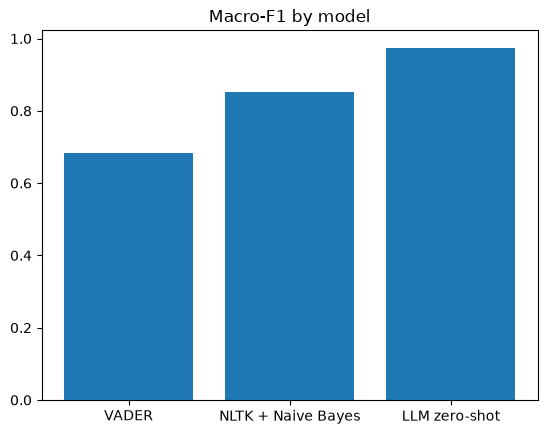

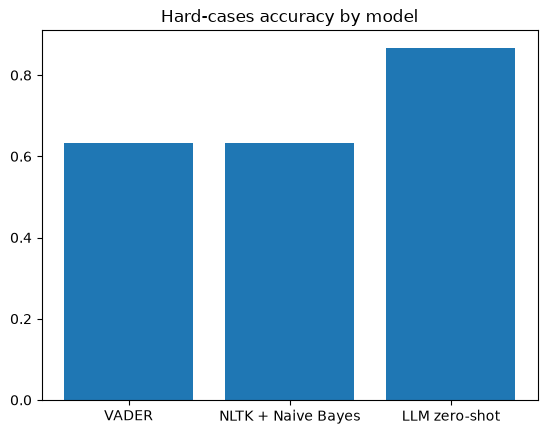

In [59]:
plt.bar(results["Model"], results["Macro-F1"])
plt.title("Macro-F1 by model")
plt.savefig("chart_macro_f1.png")
plt.show()

plt.bar(results["Model"], results["Hard cases acc."])
plt.title("Hard-cases accuracy by model")
plt.savefig("chart_hard_cases.png")
plt.show()

In [60]:
pd.set_option("display.max_colwidth", 200)       # show more of each review

# --- VADER's mistakes ---
vader_preds = pd.read_csv("test_300_with_vader.csv")
vader_wrong = vader_preds[vader_preds["y"] != vader_preds["vader_pred"]]

print("VADER got", len(vader_wrong), "wrong out of 300")
print(vader_wrong[["y", "vader_pred", "text"]].head(8))

VADER got 88 wrong out of 300
           y vader_pred  \
0   negative   positive   
1   negative   positive   
2   negative   positive   
5   negative   positive   
11  negative   positive   
12  negative   positive   
14  negative   positive   
15  negative   positive   

                                                                                                                                                                                                       text  
0   I bought the buffet all day pass m decided to try out this place. Not one of the best buffets that I have been to. I love seafood but I'm not sure what the buzz was about the crab legs. For the pr...  
1   I don't even know where to begin. Archi's has never failed me before, but this was my first time at this location. My family took Dan T. and I here for a Sunday afternoon lunch. My parents were ig...  
2   The food was actually great, this review is for the service. \nI was actually blown away by the terrible

In [61]:
# --- Naive Bayes mistakes ---
nb_preds = pd.read_csv("test_300_with_nb.csv")
nb_wrong = nb_preds[nb_preds["y"] != nb_preds["nb_pred"]]

print("Naive Bayes got", len(nb_wrong), "wrong out of 300")
print(nb_wrong[["y", "nb_pred", "text"]].head(8))

# --- LLM mistakes ---
llm_preds = pd.read_csv("test_300_with_llm.csv")
llm_wrong = llm_preds[llm_preds["y"] != llm_preds["llm_pred"]]

print("LLM got", len(llm_wrong), "wrong out of 300")
print(llm_wrong[["y", "llm_pred", "text"]].head(8))

Naive Bayes got 44 wrong out of 300
           y   nb_pred  \
0   negative  positive   
9   positive  negative   
20  positive  negative   
35  negative  positive   
37  positive  negative   
54  positive  negative   
61  negative  positive   
69  negative  positive   

                                                                                                                                                                                                       text  
0   I bought the buffet all day pass m decided to try out this place. Not one of the best buffets that I have been to. I love seafood but I'm not sure what the buzz was about the crab legs. For the pr...  
9   Always make a 7 AM appointment (for fasting tests) and usually get called in within 5 minutes of appointment time. Consistently good. We always go to the location at Lake Mead and Buffalo. Staff i...  
20  Dined here last night. The food was very good indeed (lamb kurma, chicken saag, and a few other dishes), we

In [62]:
print([f for f in os.listdir(".") if f.endswith(".csv")])

['hard_cases.csv', 'hard_cases_with_nb.csv', 'hard_cases_with_vader.csv', 'results_llm.csv', 'results_nb.csv', 'results_table.csv', 'results_vader.csv', 'test.csv', 'test_300.csv', 'test_300_with_llm.csv', 'test_300_with_nb.csv', 'test_300_with_vader.csv', 'train.csv']


In [63]:
hard_vader = pd.read_csv("hard_cases_with_vader.csv")
print(hard_vader[hard_vader["y"] != hard_vader["vader_pred"]][["text", "y", "vader_pred"]])

                                                             text         y  \
1                Oh great, another hour-long wait for cold fries.  negative   
3                            I wouldn’t say the service was good.  negative   
6                   Wow, I love paying $30 for a lukewarm burger.  negative   
10                                 I wish the service was better.  negative   
12                The preperation time for the food took a while.  negative   
17               I found both the service and the food as average  negative   
19                      The provided incredible customer service!  posotive   
20                    The atmosphere didn't match the food at all  negative   
21  They didn't provide any options for milder flavors of noodles  negative   
22           The pasta came out a little overcooked in my opinion  negative   
23   The seafood selection was didn't have a non-shellfish option  negative   

   vader_pred  
1    positive  
3    positive  
6  